For b = 0 Å: Ground State Energy E = 95.620 eV
For b = 10 Å: Ground State Energy E = 99.271 eV
For b = 30 Å: Ground State Energy E = 105.798 eV


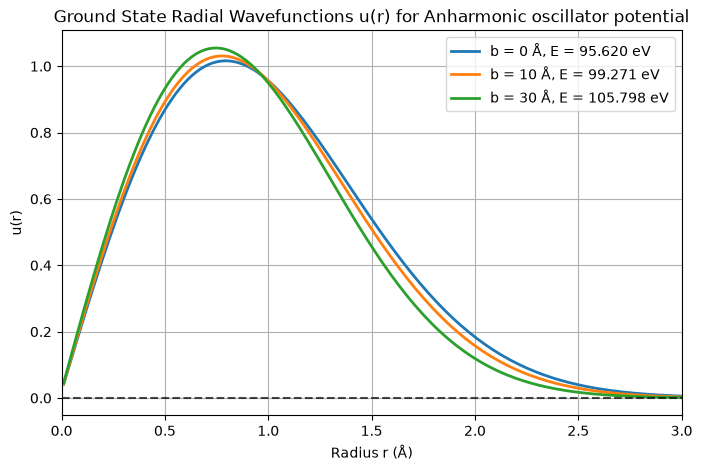

In [7]:
import numpy as np 
import matplotlib.pyplot as plt


hbar_c = 197.3                # ħc in MeV 
m = 940                         # in MeV/c^2
hbar2_over_2m = (hbar_c**2) / (2.0 * m)  
k = 100                         # in MeV fm-2


N = 1000
r_min = 0.01                    # in Å
r_max = 20.0                    # in Å
r = np.linspace(r_min, r_max, N)
h = r[1] - r[0]                 # Step size

# Finite difference Kinetic Energy operator matrix
main_diag = 2.0 * np.ones(N)
off_diag = -1.0 * np.ones(N - 1)
K = (hbar2_over_2m / (h**2)) * (np.diag(main_diag) + np.diag(off_diag, 1) + np.diag(off_diag, -1))


b_values = [0, 10, 30] # in MeV fm^-3

plt.figure(figsize=(8, 5))

for b in b_values:
    V = 0.5*k*r**2 + (1/3)*b*r**3 # Anharmonic oscillator potential
    H = K + np.diag(V)
    energies, wavefunctions = np.linalg.eigh(H)
    E_ground = energies[0]
    u = wavefunctions[:, 0] / np.sqrt(h)
    if u[1] < 0:
        u = -u
    print(f"For b = {b} Å: Ground State Energy E = {E_ground:.3f} eV")
    plt.plot(r, u, label=f"b = {b} Å, E = {E_ground:.3f} eV", linewidth=2)

plt.axhline(0, color='black', linestyle='--', alpha=0.7)
plt.title("Ground State Radial Wavefunctions u(r) for Anharmonic oscillator potential")
plt.xlabel("Radius r (Å)")
plt.ylabel("u(r)")
plt.xlim(0, 3)
plt.legend()
plt.grid(True)
plt.show()